# Auditing a CV screener for gender bias

This notebook tells the whole audit from the results saved in `results/`. It loads no model and
runs on a CPU. Every number in the text is read from a result file when the notebook runs.
The same story, with more detail, is in `docs/results.md`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results").is_dir())
RESULTS = ROOT / "results"
PER = 100  # shares are told as "of every 100"
HOUR = 3600  # seconds


def read_json(name):
    return json.loads((RESULTS / name).read_text(encoding="utf-8"))


def read_csv(name):
    return pd.read_csv(RESULTS / name)


def show_figure(name):
    display(Image(filename=str(RESULTS / "figures" / name), width=520))


def say(text):
    display(Markdown(text))


def name(job):
    return job.replace("_", " ")


def listing(items):
    items = list(items)
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]


def pct(share, digits=0):
    return f"{PER * share:.{digits}f}%"


def ci(stat, digits=2, scale=1, sign=False, unit=""):
    """`value [low, high]` of a result that has `value`, `ci_low` and `ci_high`."""
    flag = "+" if sign else ""
    value, low, high = (scale * stat[key] for key in ("value", "ci_low", "ci_high"))
    return f"{value:{flag}.{digits}f}{unit} [{low:{flag}.{digits}f}, {high:{flag}.{digits}f}]"


def md_table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(cell) for cell in row) + " |" for row in rows]
    return "\n".join(lines)


alpha = read_json("gap_statistics.json")["main_model"]["alpha"]
LEVEL_NUMBER = round(PER * (1 - alpha))
LEVEL = f"{LEVEL_NUMBER}%"

## What the screener does, and the data

**Why I look at it.** A recruiter searches for a job, say surgeon. An AI model reads each
candidate's short professional bio and decides which job it describes. Bios it labels "surgeon"
go on to the recruiter; the rest are set aside and no person sees them. A candidate is qualified
for a search when the bio belongs to someone who really does that job. A fair screener passes on
the same share of qualified women and qualified men.

In [2]:
data = read_json("data_summary.json")
bios, share = data["bios"], data["share_women_train"]
subset = data["counts"]["showcase_subset"]
lowest, highest = min(share, key=share.get), max(share, key=share.get)
say(
    "**How this was run.** `uv run python scripts/prepare_data.py` downloads Bias in Bios at a "
    f"pinned revision and draws {bios['train']:,} training, {bios['dev']:,} development and "
    f"{bios['test']:,} test bios, stratified by job and gender with a fixed seed. The models "
    "never see the test bios while they train."
)

**How this was run.** `uv run python scripts/prepare_data.py` downloads Bias in Bios at a pinned revision and draws 60,000 training, 10,000 development and 99,069 test bios, stratified by job and gender with a fixed seed. The models never see the test bios while they train.

In [3]:
rows = [
    [name(job), pct(share[job]), f"{subset[job]['female']:,}", f"{subset[job]['male']:,}"]
    for job in subset
]
say(
    f"**What I found.** The data are professional bios from Bias in Bios, each labelled with one "
    f"of {len(share)} jobs and a gender inferred from its pronouns. Jobs are far from balanced: "
    f"women are {pct(share[lowest])} of the training bios for {name(lowest)} and "
    f"{pct(share[highest])} for {name(highest)}. The explanations later run on a fixed subset of "
    f"{bios['showcase_subset']:,} test bios from the jobs below."
)
say(
    md_table(
        ["Job", "Women in the training bios", "Women in the subset", "Men in the subset"], rows
    )
)

**What I found.** The data are professional bios from Bias in Bios, each labelled with one of 28 jobs and a gender inferred from its pronouns. Jobs are far from balanced: women are 9% of the training bios for rapper and 93% for dietitian. The explanations later run on a fixed subset of 1,721 test bios from the jobs below.

| Job | Women in the training bios | Women in the subset | Men in the subset |
|---|---|---|---|
| composer | 16% | 150 | 150 |
| dietitian | 93% | 150 | 71 |
| model | 83% | 150 | 150 |
| nurse | 91% | 150 | 150 |
| software engineer | 16% | 150 | 150 |
| surgeon | 15% | 150 | 150 |

**What it means.** Most jobs lean strongly towards one gender, so counting how many women and men
a model passes on would only repeat the imbalance of the data. I compare the share of qualified
women passed on with the share of qualified men passed on, which stays fair to a job with few
women.

## How good are the screeners?

**Why I look at it.** Before asking whether the screener is fair, I need to know how often it is
right. I compare screeners: the main model is a transformer, and the baseline model is a
simpler one that counts words, so I can see whether more accuracy brings more fairness.

In [4]:
baseline, main = read_json("metrics_baseline.json"), read_json("metrics_deberta.json")
settings, base_settings = main["hyperparameters"], baseline["hyperparameters"]
say(
    "**How this was run.** The baseline model counts words (TF-IDF) and weighs them with "
    "logistic regression: `uv run python scripts/train_baseline.py`, regularization parameter C = "
    f"{base_settings['C']}, words kept when at least {base_settings['min_df']} bios use them. The "
    "main model is DeBERTa-v3-small fine-tuned with `uv run python scripts/train_deberta.py`: "
    f"learning rate {settings['learning_rate']:g}, {settings['epochs']} epochs, batches of "
    f"{settings['effective_batch_size']}, seed {settings['seed']}, the best checkpoint at step "
    f"{settings['best_step']:,}. Intervals are {LEVEL} bootstrap intervals over bios."
)

**How this was run.** The baseline model counts words (TF-IDF) and weighs them with logistic regression: `uv run python scripts/train_baseline.py`, regularization parameter C = 256, words kept when at least 5 bios use them. The main model is DeBERTa-v3-small fine-tuned with `uv run python scripts/train_deberta.py`: learning rate 3e-05, 5 epochs, batches of 32, seed 42, the best checkpoint at step 9,375. Intervals are 95% bootstrap intervals over bios.

In [5]:
compare = main["comparison_with_baseline"]
assert not compare["macro_f1"]["cis_overlap"] and compare["rms_tpr_gap"]["cis_overlap"]


def screener_row(label, metrics):
    test = metrics["test"]
    return [
        label,
        ci(test["accuracy"], 1, PER),
        ci(test["macro_f1"], 3),
        ci(test["rms_tpr_gap"], 3),
    ]


say(
    f"**What I found.** On {bios['test']:,} bios the models never saw, the main model gives the "
    f"right job for {PER * main['test']['accuracy']['value']:.1f} of every {PER} bios and the "
    f"baseline model for {PER * baseline['test']['accuracy']['value']:.1f}. The macro-F1 "
    "intervals do not overlap. The gender gap is lower for the main model, but its interval "
    "overlaps the baseline's."
)
say(
    md_table(
        ["Screener", f"Right job, of every {PER} bios", "Macro-F1", "Gender gap (RMS TPR gap)"],
        [screener_row("Baseline model", baseline), screener_row("Main model", main)],
    )
)

**What I found.** On 99,069 bios the models never saw, the main model gives the right job for 83.7 of every 100 bios and the baseline model for 79.5. The macro-F1 intervals do not overlap. The gender gap is lower for the main model, but its interval overlaps the baseline's.

| Screener | Right job, of every 100 bios | Macro-F1 | Gender gap (RMS TPR gap) |
|---|---|---|---|
| Baseline model | 79.5 [79.3, 79.8] | 0.728 [0.724, 0.733] | 0.167 [0.151, 0.190] |
| Main model | 83.7 [83.5, 83.9] | 0.783 [0.779, 0.788] | 0.148 [0.134, 0.172] |

**What it means.** Macro-F1 averages quality over the jobs, so small jobs count as much as large
ones, and the main model is clearly better on it. The gender gap sums up, over all jobs, how far
the share of qualified women passed on is from the share of qualified men: zero would be equal
treatment. The gaps of both models are not clearly different, so the data does not show that
the more accurate model is fairer.

## Is it biased?

**Why I look at it.** Among people who really do a job, does the model pass on women and men at
the same rate? For each job I take the test bios of people in it and count the share of
women and the share of men the model passes on. Above zero the model favours women,
below zero it favours men. F1 plots this gap for every job against the share of women in it.

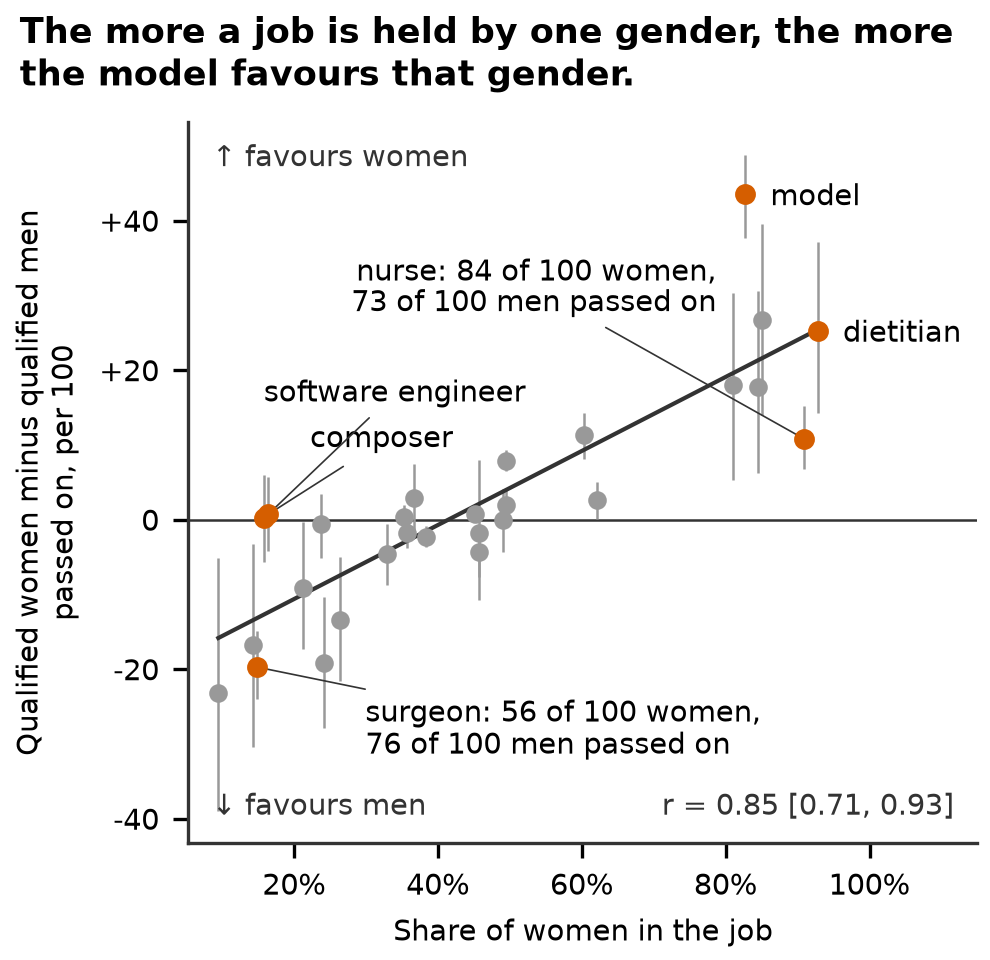

In [6]:
show_figure("f1_gap_vs_share.png")

In [7]:
stats = read_json("gap_statistics.json")["main_model"]
shuffled = stats["rms_tpr_gap"]
say(
    "**How this was run.** `uv run python scripts/figure_f1.py` plots the rates saved in "
    "`results/metrics_deberta.json`. `uv run python scripts/gap_statistics.py` adds the "
    f"statistics: {stats['n_bootstrap']:,} bootstrap resamples and {shuffled['n_permutations']:,} "
    f"shuffles of gender within each job, with {LEVEL} intervals."
)

**How this was run.** `uv run python scripts/figure_f1.py` plots the rates saved in `results/metrics_deberta.json`. `uv run python scripts/gap_statistics.py` adds the statistics: 1,000 bootstrap resamples and 1,000 shuffles of gender within each job, with 95% intervals.

In [8]:
per_job = main["test"]["per_occupation"]


def passed_on(job):
    rates = per_job[job]
    return (
        f"{PER * rates['tpr_female']['value']:.0f} of every {PER} women and "
        f"{PER * rates['tpr_male']['value']:.0f} of every {PER} men"
    )


pearson = stats["pearson"]
women = [
    name(j) for j, o in stats["occupations"].items() if o["p_holm"] < alpha and o["tpr_gap"] > 0
]
men = [name(j) for j, o in stats["occupations"].items() if o["p_holm"] < alpha and o["tpr_gap"] < 0]
assert pearson["fisher_ci_low"] > 0 and shuffled["p_value"] < alpha
say(
    f"**What I found.** Among people who really are surgeons, the model passes on "
    f"{passed_on('surgeon')}. Among nurses it passes on {passed_on('nurse')}. Across the jobs, "
    "the more women hold a job, the more the model favours women in it: the correlation is "
    f"{pearson['value']:.2f} ({LEVEL} interval {pearson['fisher_ci_low']:.2f} to "
    f"{pearson['fisher_ci_high']:.2f})."
)
say(
    f"To check that chance does not explain this, I shuffled the genders within each job "
    f"{shuffled['n_permutations']:,} times. The overall gap of the shuffled data was "
    f"{shuffled['null_mean']:.3f} on average and {shuffled['null_p95']:.3f} at the "
    f"{LEVEL_NUMBER}th percentile; the real gap is {shuffled['observed']:.3f}. No shuffle reached "
    f"it, so the probability that chance explains it is at most "
    f"{shuffled['p_value']:.3f}, the smallest this test can show."
)
say(
    f"Taking each of the {stats['n_occupations']} jobs on its own, with a stricter bar because I "
    f"test them all at once (Holm correction), {stats['n_significant_holm']} jobs have a gap that "
    f"is clearly not zero. The model favours women in {listing(women)}, and men in "
    f"{listing(men)}. In the other jobs the gap is too small to tell from zero with this data, "
    "which does not mean it is zero."
)

**What I found.** Among people who really are surgeons, the model passes on 56 of every 100 women and 76 of every 100 men. Among nurses it passes on 84 of every 100 women and 73 of every 100 men. Across the jobs, the more women hold a job, the more the model favours women in it: the correlation is 0.85 (95% interval 0.71 to 0.93).

To check that chance does not explain this, I shuffled the genders within each job 1,000 times. The overall gap of the shuffled data was 0.036 on average and 0.049 at the 95th percentile; the real gap is 0.148. No shuffle reached it, so the probability that chance explains it is at most 0.001, the smallest this test can show.

Taking each of the 28 jobs on its own, with a stricter bar because I test them all at once (Holm correction), 10 jobs have a gap that is clearly not zero. The model favours women in dietitian, model, nurse, paralegal, physician and teacher, and men in attorney, chiropractor, pastor and surgeon. In the other jobs the gap is too small to tell from zero with this data, which does not mean it is zero.

**What it means.** The model favours the majority gender of each job, and favours it more the
larger the majority is. Chance does not produce gaps this large. A recruiter who searches for
surgeons gets a smaller share of the qualified women than of the qualified men, and the reverse
holds for nurses.

## Why is it biased?

**Why I look at it.** To see which words drive a decision, I use Shapley values. The score of a
bio is split among its words: each word gets what it adds to or takes from the score, averaged
over many orders in which the words could be revealed. Here a word that is absent is deleted
from the text. The parts add up exactly to the score. F2 shows a wrong decision for a woman and one for a man, and F3 adds
the words up over many bios to see how the gap between women and men is made.

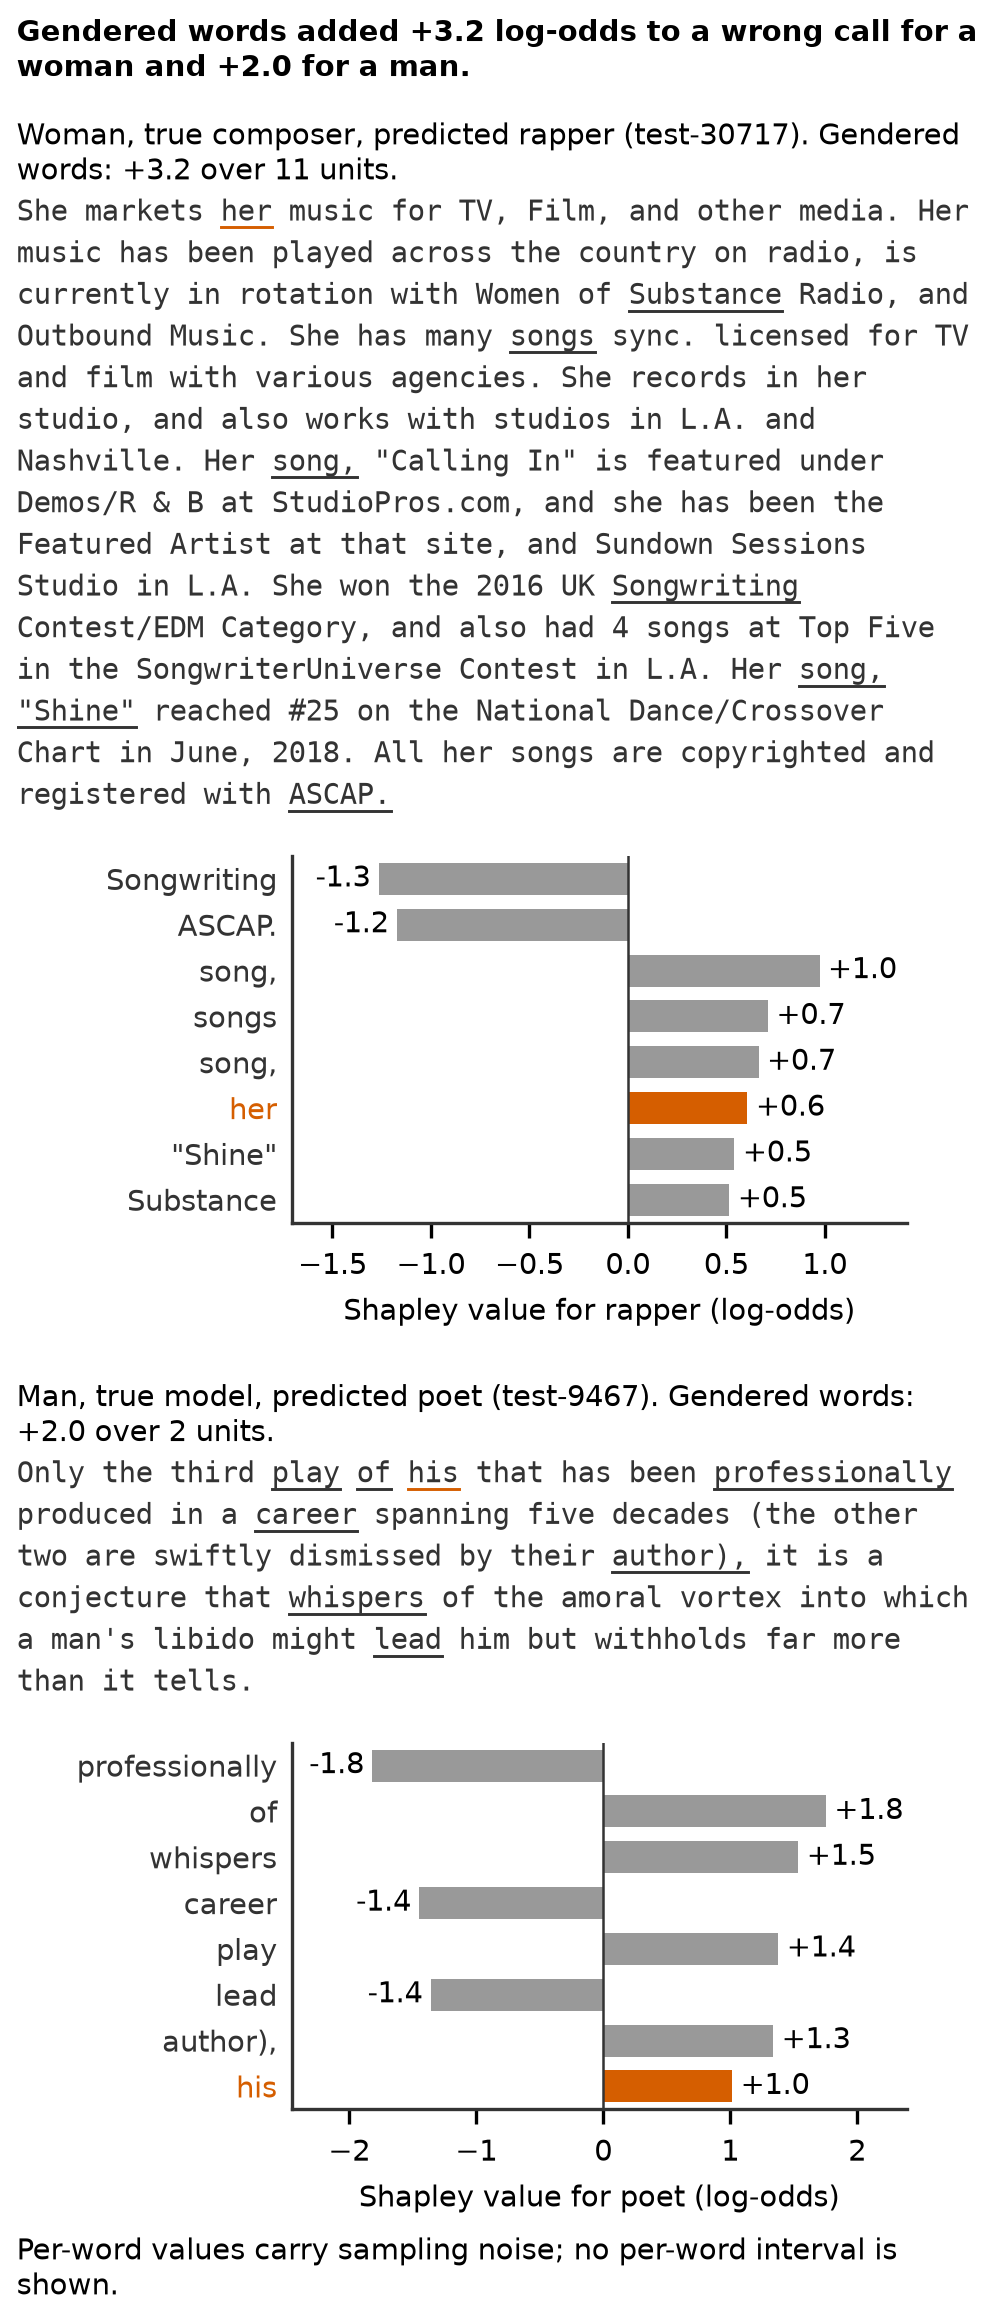

In [9]:
show_figure("f2_shapley_cases.png")

In [10]:
shapley = read_json("shapley_summary.json")
explained = read_json("gap_explained.json")
say(
    "**How this was run.** `uv run python scripts/shapley_run.py` computes the values for "
    f"{shapley['screeners']['deberta']['n_bios']:,} showcase bios of the main model: "
    f"{shapley['settings']['n_permutations']} random orders per bio, words "
    f"{shapley['settings']['removal']}d, seed {shapley['settings']['seed']}. "
    "`uv run python scripts/figure_f2.py` picks the bios and "
    "`uv run python scripts/gap_decomposition.py` splits the gap into words, with "
    f"{explained['settings']['n_boot']:,} bootstrap resamples. The parts add up to the gap to "
    f"within {explained['max_decomposition_error']:.0e}."
)

**How this was run.** `uv run python scripts/shapley_run.py` computes the values for 1,721 showcase bios of the main model: 40 random orders per bio, words deleted, seed 42. `uv run python scripts/figure_f2.py` picks the bios and `uv run python scripts/gap_decomposition.py` splits the gap into words, with 1,000 bootstrap resamples. The parts add up to the gap to within 3e-15.

In [11]:
cases = read_json("f2_cases.json")
woman, man = cases["women_in_male_dominated"], cases["men_in_female_dominated"]
say(
    "**What I found.** F2 shows a woman's bio and a man's bio that the main model got wrong, "
    "picked by a rule fixed before I looked: in each group, the wrong decision where gender "
    "words (she, he, her, his, Mr, Ms and the like) add the most to the wrong job's score. "
    f"The woman (`{woman['pick']['bio_id']}`) "
    f"is a {woman['pick']['true']} whom the model labelled a {woman['pick']['predicted']}; her "
    f"gender words add {woman['pick']['gendered_push']:+.1f} to the score for "
    f"{woman['pick']['predicted']}. The man (`{man['pick']['bio_id']}`) is a "
    f"{man['pick']['true']} labelled a {man['pick']['predicted']}; his gender words add "
    f"{man['pick']['gendered_push']:+.1f}. They are the most extreme of {woman['n_wrong']} and "
    f"{man['n_wrong']} wrong decisions, chosen to illustrate, not typical cases."
)

**What I found.** F2 shows a woman's bio and a man's bio that the main model got wrong, picked by a rule fixed before I looked: in each group, the wrong decision where gender words (she, he, her, his, Mr, Ms and the like) add the most to the wrong job's score. The woman (`test-30717`) is a composer whom the model labelled a rapper; her gender words add +3.2 to the score for rapper. The man (`test-9467`) is a model labelled a poet; his gender words add +2.0. They are the most extreme of 114 and 154 wrong decisions, chosen to illustrate, not typical cases.

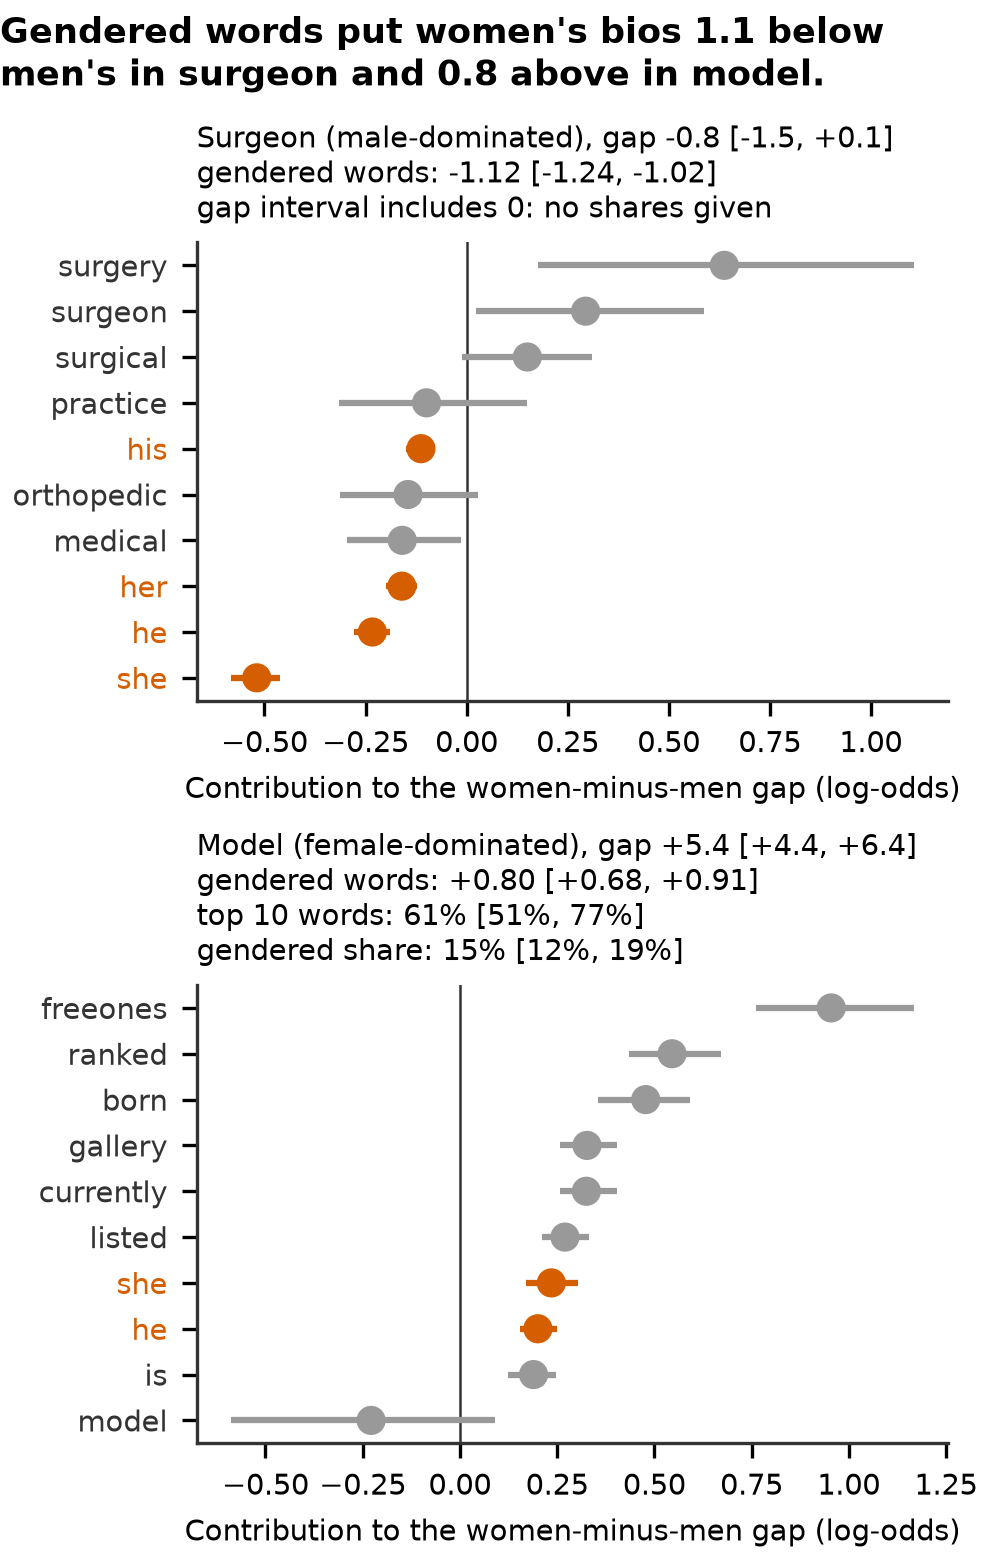

In [12]:
show_figure("f3_gap_words.png")

In [13]:
main_gaps = explained["screeners"]["deberta"]
rows = [
    [name(job), ci(g["score_gap"], sign=True), ci(g["gendered_sum"], sign=True)]
    for job, g in main_gaps.items()
]
say(
    "**F3.** For each job I study in detail, the score gap is the main model's average score for "
    "that job in women's bios minus the average in men's bios, so a positive gap favours women. "
    "Because Shapley values add up exactly, the gap splits into one part per word. The table "
    "gives the part of all the gender words together."
)
say(md_table(["Job", "Score gap, in log-odds", "Part of the gender words"], rows))

**F3.** For each job I study in detail, the score gap is the main model's average score for that job in women's bios minus the average in men's bios, so a positive gap favours women. Because Shapley values add up exactly, the gap splits into one part per word. The table gives the part of all the gender words together.

| Job | Score gap, in log-odds | Part of the gender words |
|---|---|---|
| composer | -0.16 [-0.86, +0.54] | -1.09 [-1.21, -0.96] |
| dietitian | +2.34 [+1.08, +3.68] | +0.92 [+0.79, +1.04] |
| model | +5.40 [+4.44, +6.40] | +0.80 [+0.68, +0.91] |
| nurse | +1.31 [+0.32, +2.34] | +1.97 [+1.80, +2.14] |
| software engineer | -0.21 [-0.92, +0.51] | +0.05 [-0.06, +0.16] |
| surgeon | -0.77 [-1.54, +0.08] | -1.12 [-1.24, -1.02] |

In [14]:
panels = read_json("f3_panels.json")["picked"]
decomposition = read_csv("gap_decomposition.csv")
under, over = panels["male_dominated"], panels["female_dominated"]
words_under = main_gaps[under]["gendered_sum"]
words_over = main_gaps[over]["gendered_sum"]
top_word = main_gaps[over]["top_words"][0]
row = decomposition[
    (decomposition.screener == "deberta")
    & (decomposition.occupation == over)
    & (decomposition.word == top_word)
].iloc[0]
in_women = round(row.freq_female * main_gaps[over]["n_female"])
in_men = round(row.freq_male * main_gaps[over]["n_male"])
assert words_under["ci_high"] < 0 < words_over["ci_low"] and in_men == 0
say(
    f"In {name(under)} bios, the gender words alone put women's scores "
    f"{abs(words_under['value']):.2f} below men's ({LEVEL} interval "
    f"{abs(words_under['ci_high']):.2f} to "
    f"{abs(words_under['ci_low']):.2f}). In {name(over)} bios, women score "
    f"{main_gaps[over]['score_gap']['value']:.2f} higher; the gender words account for "
    f"{words_over['value']:+.2f} of that ({pct(main_gaps[over]['gendered_share']['value'])}). The "
    f"strongest single word there is `{top_word}`, the name of a website that lists adult "
    f"performers. It appears in {in_women} of the {main_gaps[over]['n_female']} women's bios "
    f"and in {in_men} of the {main_gaps[over]['n_male']} men's, and its part of the gap is "
    f"{row.contribution:+.2f}. The counts show that the word appears only in women's bios; they "
    "do not show where the bios came from."
)

In surgeon bios, the gender words alone put women's scores 1.12 below men's (95% interval 1.02 to 1.24). In model bios, women score 5.40 higher; the gender words account for +0.80 of that (15%). The strongest single word there is `freeones`, the name of a website that lists adult performers. It appears in 54 of the 150 women's bios and in 0 of the 150 men's, and its part of the gap is +0.95. The counts show that the word appears only in women's bios; they do not show where the bios came from.

**What it means.** The gender words push the decision towards the majority gender of the job: in
jobs held mostly by men they pull women's scores down, and in jobs held mostly by women they push
them up. Not every cue is a gender word. The website name is a proxy: it stands in for gender
because only women's bios carry it. The split says how the gap is made up, not what would happen
if a word were edited; the next section tests that. See ADR 0003 and ADR 0004 for the design.

## Does changing only the gender change the decision?

**Why I look at it.** F3 shows how the scores split; this tests what happens when the gender in a
bio changes. For each showcase bio I make a copy with the gender swapped (he and she, him and
her, his and hers, Mr and Ms) and ask both models again. A changed decision is a flip. Any edit
can flip a borderline decision, so I also make a copy where the same words are deleted instead of
swapped. If the swap flips more decisions than the deletion, the model reacts to the gender
itself and not just to the edit.

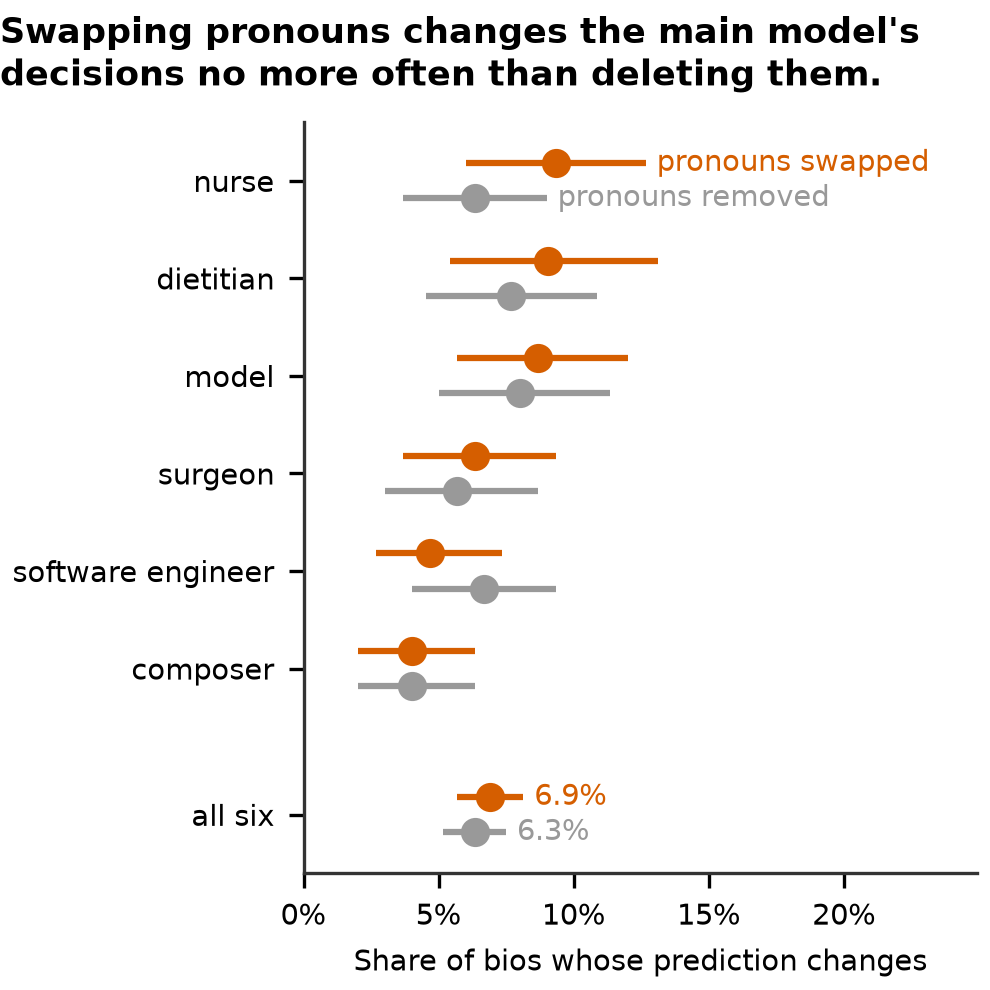

In [15]:
show_figure("f4_flip_rates.png")

In [16]:
flips = read_csv("counterfactual_gender.csv")
counterfactual = read_json("counterfactual_gender.json")
checked, flagged = counterfactual["hand_check"], counterfactual["flags"]
say(
    "**How this was run.** `uv run python scripts/counterfactual_gender.py` asks both models "
    f"again on the swapped and the deleted copies, with {counterfactual['settings']['n_boot']:,} "
    f"bootstrap resamples and seed {counterfactual['settings']['seed']}. Checks on the "
    f"swapped text: {flagged['n_flagged']:,} of the {flagged['n_bios']:,} bios keep another "
    f"gender clue ({flagged['n_noun']} by a gender noun, {flagged['n_name']} by a first name), and "
    "`uv run python scripts/counterfactual_hand_check.py` prints "
    f"{checked['n']} swapped bios that I read by hand: {checked['n_incoherent']} read wrongly."
)

**How this was run.** `uv run python scripts/counterfactual_gender.py` asks both models again on the swapped and the deleted copies, with 1,000 bootstrap resamples and seed 42. Checks on the swapped text: 752 of the 1,721 bios keep another gender clue (225 by a gender noun, 631 by a first name), and `uv run python scripts/counterfactual_hand_check.py` prints 50 swapped bios that I read by hand: 3 read wrongly.

In [17]:
def flip(screener, job, condition, column="flip_rate"):
    row = flips[
        (flips.screener == screener)
        & (flips.occupation == job)
        & (flips.condition == condition)
        & (flips.subset == "all")
    ].iloc[0]
    return {
        "value": row[column],
        "ci_low": row[f"{column}_ci_low"],
        "ci_high": row[f"{column}_ci_high"],
    }


jobs = [job for job in flips.occupation.unique() if job != "pooled"]
overlap = [
    flip("deberta", job, "swap")["ci_low"] <= flip("deberta", job, "removal")["ci_high"]
    and flip("deberta", job, "removal")["ci_low"] <= flip("deberta", job, "swap")["ci_high"]
    for job in jobs
]
assert all(overlap)
assert (
    flip("baseline", "pooled", "swap")["ci_low"] > flip("baseline", "pooled", "removal")["ci_high"]
)
rows = [
    [
        "All jobs together" if job == "pooled" else name(job),
        *(
            ci(flip(screener, job, condition), 1, PER, unit="%")
            for screener in ("deberta", "baseline")
            for condition in ("swap", "removal")
        ),
    ]
    for job in [*jobs, "pooled"]
]
say(
    f"**What I found.** The table gives the share of {bios['showcase_subset']:,} decisions that "
    f"flip, with {LEVEL} intervals. For the main model the swap flips "
    f"{pct(flip('deberta', 'pooled', 'swap')['value'], 1)} of the decisions and the deletion "
    f"{pct(flip('deberta', 'pooled', 'removal')['value'], 1)}, and the intervals overlap in every "
    f"job. For the baseline model the swap flips "
    f"{pct(flip('baseline', 'pooled', 'swap')['value'], 1)} "
    f"and the deletion {pct(flip('baseline', 'pooled', 'removal')['value'], 1)}."
)
say(
    md_table(
        ["Job", "Main model: swap", "Main model: deletion", "Baseline: swap", "Baseline: deletion"],
        rows,
    )
)

**What I found.** The table gives the share of 1,721 decisions that flip, with 95% intervals. For the main model the swap flips 6.9% of the decisions and the deletion 6.3%, and the intervals overlap in every job. For the baseline model the swap flips 13.5% and the deletion 8.8%.

| Job | Main model: swap | Main model: deletion | Baseline: swap | Baseline: deletion |
|---|---|---|---|---|
| composer | 4.0% [2.0, 6.3] | 4.0% [2.0, 6.3] | 9.7% [6.3, 13.0] | 6.7% [4.0, 9.7] |
| dietitian | 9.0% [5.4, 13.1] | 7.7% [4.5, 10.9] | 12.2% [8.1, 16.7] | 7.2% [4.1, 10.9] |
| model | 8.7% [5.7, 12.0] | 8.0% [5.0, 11.3] | 17.3% [13.0, 21.7] | 8.0% [5.0, 11.0] |
| nurse | 9.3% [6.0, 12.7] | 6.3% [3.7, 9.0] | 15.7% [11.7, 20.0] | 11.7% [8.3, 15.3] |
| software engineer | 4.7% [2.7, 7.3] | 6.7% [4.0, 9.3] | 13.3% [10.0, 17.0] | 10.3% [7.3, 13.7] |
| surgeon | 6.3% [3.7, 9.3] | 5.7% [3.0, 8.7] | 12.7% [9.0, 16.3] | 8.7% [5.7, 12.0] |
| All jobs together | 6.9% [5.7, 8.1] | 6.3% [5.2, 7.5] | 13.5% [12.0, 15.1] | 8.8% [7.6, 10.1] |

In [18]:
change = flip("deberta", "pooled", "swap", "mean_log_odds_change")
toward = {
    (screener, condition): flip(screener, "pooled", condition, "toward_share")
    for screener in ("deberta", "baseline")
    for condition in ("swap", "removal")
}
say(
    "When the main model flips after a swap, the new job is one held more by the new gender "
    f"{pct(toward['deberta', 'swap']['value'])} of the time ({LEVEL} interval "
    f"{pct(toward['deberta', 'swap']['ci_low'])} to {pct(toward['deberta', 'swap']['ci_high'])}). "
    "That partly reflects where these jobs sit, at the extremes of the gender split, so I read "
    "the deletion copies the same way: "
    f"{pct(toward['deberta', 'removal']['value'])} "
    f"({pct(toward['deberta', 'removal']['ci_low'])} to "
    f"{pct(toward['deberta', 'removal']['ci_high'])}). The swap does not move the main model's "
    f"score for the true job on average: {ci(change, sign=True)} log-odds."
)

When the main model flips after a swap, the new job is one held more by the new gender 88% of the time (95% interval 82% to 94%). That partly reflects where these jobs sit, at the extremes of the gender split, so I read the deletion copies the same way: 72% (63% to 80%). The swap does not move the main model's score for the true job on average: +0.03 [-0.01, +0.08] log-odds.

**What it means.** For the main model most flips come from editing the text, and this data shows
no extra reaction to the gender itself. The baseline model reacts more to the swap than to the
deletion: it reads the pronouns as evidence for a job. When a swap does flip a decision, it leans
towards a job typical of the new gender further than an edit alone explains. A swap between a woman's and a man's
pronouns says nothing about non-binary people, and the hand check cannot rule out rare errors in
the swapped text. See ADR 0005.

## Can the explanations be trusted?

**Why I look at it.** The earlier sections rest on Shapley values, so before I rely on them I ask:
do the words with high values matter to the model? does the ranking of the
words stay the same if I compute it again, or in another reasonable way? F5 answers both.

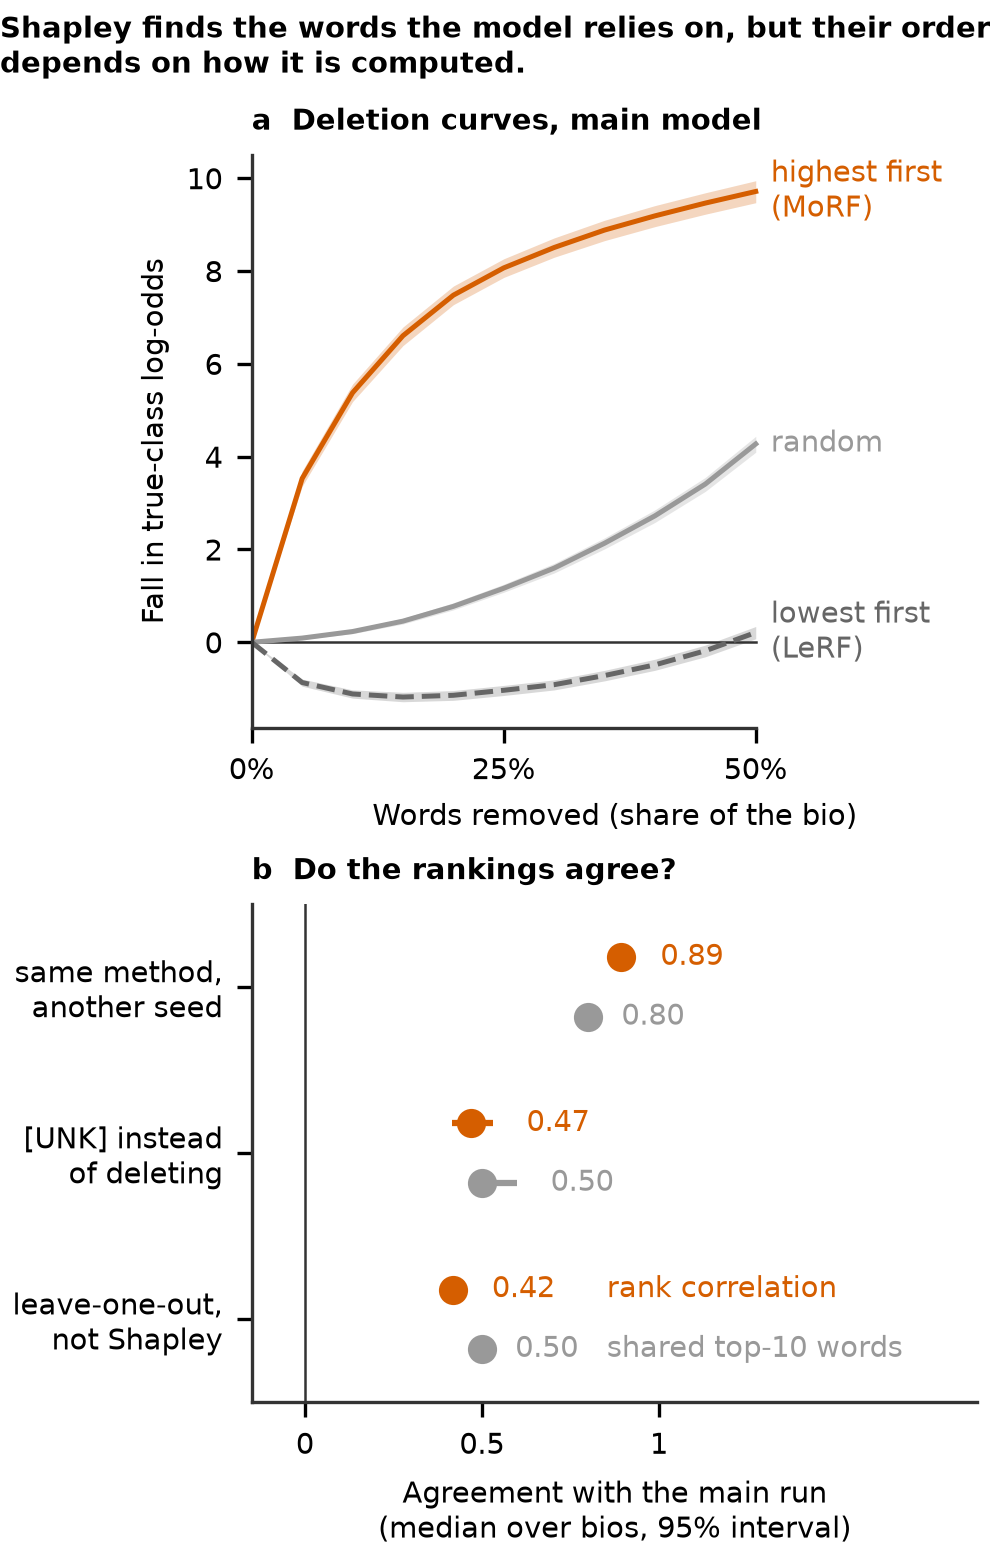

In [19]:
show_figure("f5_explanation_checks.png")

In [20]:
areas = read_json("deletion_areas.json")
stability = read_json("stability.json")
curves = read_csv("deletion_curves.csv")
say(
    "**How this was run.** `uv run python scripts/deletion_curves.py` removes up to "
    f"{max(areas['percents'])}% of the words of {areas['n_bios']:,} bios, replacing each by "
    f"`[UNK]`, in the order of the Shapley values, the reverse order and random "
    f"(random: {areas['n_random_orders']} orders per bio). "
    "`uv run python scripts/stability_runs.py` and `uv run python scripts/stability.py` recompute "
    "the ranking another way, and `uv run python scripts/figure_f5.py` draws the result. "
    f"Intervals are {LEVEL} bootstrap intervals over bios."
)

**How this was run.** `uv run python scripts/deletion_curves.py` removes up to 50% of the words of 1,721 bios, replacing each by `[UNK]`, in the order of the Shapley values, the reverse order and random (random: 10 orders per bio). `uv run python scripts/stability_runs.py` and `uv run python scripts/stability.py` recompute the ranking another way, and `uv run python scripts/figure_f5.py` draws the result. Intervals are 95% bootstrap intervals over bios.

In [21]:
drops = {s: areas["screeners"][s]["logodds_drop"]["area"] for s in ("deberta", "baseline")}
half = curves[(curves.screener == "deberta") & (curves.fraction == max(curves.fraction))]
keeps = half.set_index("order").mean_agreement
assert drops["deberta"]["morf"]["ci_low"] > drops["deberta"]["random"]["ci_high"]
say(
    "**What I found.** I remove a bio's words step by step, highest Shapley value first (MoRF), "
    "lowest first (LeRF), or at random, and measure how far the score of the true job falls, "
    f"in log-odds. Averaged over the steps, the main model's score falls by "
    f"{drops['deberta']['morf']['value']:.1f} when the top words go first, "
    f"{drops['deberta']['random']['value']:.1f} at random, and "
    f"{drops['deberta']['lerf']['value']:+.1f} when the least useful words go first. With "
    f"{pct(max(curves.fraction))} of the words gone, the main model keeps its original decision "
    f"in {pct(keeps['morf'])} of bios when the top words go first, "
    f"{pct(keeps['random'])} at random "
    f"and {pct(keeps['lerf'])} when the least useful go first."
)
say(
    md_table(
        ["Screener", "Top words first", "Random", "Least useful first"],
        [
            [label, *(ci(drops[key][order], 2) for order in ("morf", "random", "lerf"))]
            for label, key in (("Main model", "deberta"), ("Baseline model", "baseline"))
        ],
    )
)

**What I found.** I remove a bio's words step by step, highest Shapley value first (MoRF), lowest first (LeRF), or at random, and measure how far the score of the true job falls, in log-odds. Averaged over the steps, the main model's score falls by 7.0 when the top words go first, 1.5 at random, and -0.7 when the least useful words go first. With 50% of the words gone, the main model keeps its original decision in 12% of bios when the top words go first, 44% at random and 73% when the least useful go first.

| Screener | Top words first | Random | Least useful first |
|---|---|---|---|
| Main model | 6.98 [6.80, 7.15] | 1.53 [1.45, 1.61] | -0.68 [-0.76, -0.59] |
| Baseline model | 9.50 [9.29, 9.74] | 0.95 [0.89, 1.02] | -5.29 [-5.42, -5.17] |

In [22]:
checks = stability["checks"]
top = stability["settings"]["top"]
labels = {
    "seed": "Same method, another seed",
    "removal": "`[UNK]` instead of deleting the word",
    "method": "Leave-one-out instead of Shapley",
}
rows = [
    [
        labels[key],
        f"{checks[key]['n_bios']:,}",
        f"{checks[key]['spearman']['median']:.2f} "
        f"[{checks[key]['spearman']['median_ci'][0]:.2f}, "
        f"{checks[key]['spearman']['median_ci'][1]:.2f}]",
        f"{round(top * checks[key]['top10_overlap']['median'])} of {top}",
    ]
    for key in labels
]
say(
    "I compare the ranking of the main run with alternatives, bio by bio, by the rank "
    "correlation over all the words of a bio (the maximum means the same order) and by how "
    f"many of the {top} strongest words both rankings share. The table gives the median "
    "over bios."
)
say(md_table(["Compared with the main run", "Bios", "Rank correlation", "Top words shared"], rows))

I compare the ranking of the main run with alternatives, bio by bio, by the rank correlation over all the words of a bio (the maximum means the same order) and by how many of the 10 strongest words both rankings share. The table gives the median over bios.

| Compared with the main run | Bios | Rank correlation | Top words shared |
|---|---|---|---|
| Same method, another seed | 100 | 0.89 [0.88, 0.91] | 8 of 10 |
| `[UNK]` instead of deleting the word | 100 | 0.47 [0.41, 0.53] | 5 of 10 |
| Leave-one-out instead of Shapley | 1,721 | 0.42 [0.40, 0.43] | 5 of 10 |

In [23]:
example = stability["disagreement_example"]
first, second = example["occurrences"]
say(
    f"One bio shows why the methods disagree. The rule was fixed before I looked: among bios "
    f"whose top Shapley word appears at least twice, the one where Shapley and leave-one-out "
    f"disagree most. It is `{example['bio_id']}`, a {example['true_occupation']} bio of "
    f"{example['n_words']} words (rank correlation {example['spearman']:+.2f}). Shapley's top "
    f"word is *{example['word']}*, which appears twice ({first['shapley']:+.2f} and "
    f"{second['shapley']:+.2f}). Leave-one-out gives the same occurrences "
    f"{first['loo']:+.2f} and {second['loo']:+.2f}, and removing both together lowers the score "
    f"by only {example['drop_all_occurrences']:.2f}."
)

One bio shows why the methods disagree. The rule was fixed before I looked: among bios whose top Shapley word appears at least twice, the one where Shapley and leave-one-out disagree most. It is `test-73398`, a surgeon bio of 92 words (rank correlation -0.28). Shapley's top word is *practice*, which appears twice (+2.43 and +0.72). Leave-one-out gives the same occurrences -0.07 and +0.04, and removing both together lowers the score by only 0.07.

**What it means.** The words Shapley ranks highest do matter to the main model: removing them
first hurts far more than removing random words. The baseline model gives the same order, but its
check is weaker, because its TF-IDF reads `[UNK]` almost like a deleted word. The exact order of
the words in one bio, though, changes with how the values are computed, and the many words with
small values move most. Related words carry the same information: while one remains, the others
add little, so leave-one-out sees each as useless and Shapley shares the credit. I did not confirm
that by removing all the related words together. So I trust the totals over many bios, such as the gap
decomposition of F3, and I read the value of one word in one bio as an indication. I did not run
weight randomization or retraining-based evaluation (Adebayo et al., 2018; Hooker et al., 2019).

## Where does gender live inside the model?

**Why I look at it.** Removing the pronouns is the usual first fix, so is gender really gone
afterwards? And does what the model keeps about gender change its decision? A probe answers the
first question and activation patching the second. A probe is a simple classifier that tries to
guess gender from the model's internal representation of a bio at one layer. Patching copies the
internal state of the original bio into the run on the swapped bio and asks how much of the
original score comes back.

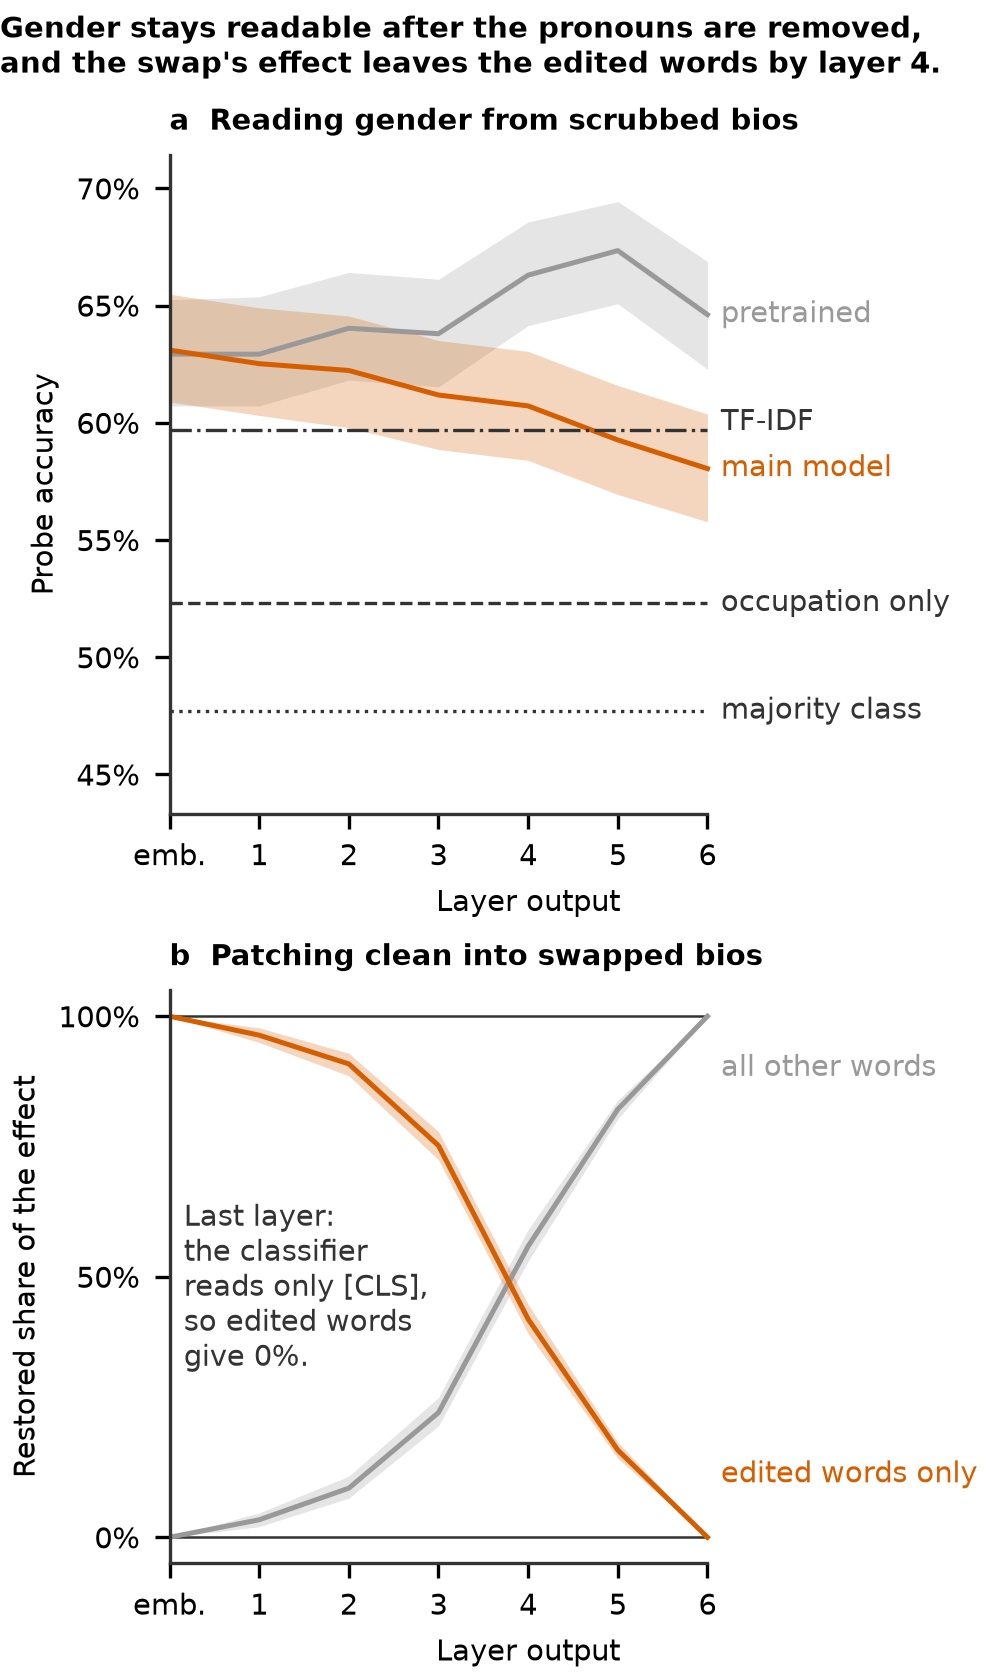

In [24]:
show_figure("f6_probing_patching.png")

In [25]:
probing_run = read_json("probing.json")
patching_run = read_json("patching.json")
probe_settings, patch_settings = probing_run["settings"], patching_run["settings"]
say(
    "**How this was run.** `uv run python scripts/probing_features.py` and "
    "`uv run python scripts/probing.py` fit one probe per layer on bios without pronouns or "
    f"titles: {probe_settings['n_train']:,} training bios, the {probe_settings['n_test']:,} "
    f"showcase bios for testing, {probe_settings['folds']}-fold choice of the regularization, "
    f"{probe_settings['n_permutations']} probes on shuffled genders as a check. "
    "`uv run python scripts/patching.py` patches the bios the swap moves most: those above the "
    f"{PER * patch_settings['quantile']:.0f}th percentile of the deletion control, "
    f"{patching_run['bar']:.2f} log-odds or more."
)

**How this was run.** `uv run python scripts/probing_features.py` and `uv run python scripts/probing.py` fit one probe per layer on bios without pronouns or titles: 10,000 training bios, the 1,721 showcase bios for testing, 5-fold choice of the regularization, 100 probes on shuffled genders as a check. `uv run python scripts/patching.py` patches the bios the swap moves most: those above the 95th percentile of the deletion control, 1.44 log-odds or more.

In [26]:
probing = read_csv("probing.csv")
probing = probing[probing.subset == "all"]
layers = sorted(probing.layer.dropna().unique())
by_model = {m: probing[probing.model == m].set_index("layer") for m in ("pretrained", "deberta")}
reference = probing[probing.model.isin(["majority", "occupation_only", "tfidf"])].set_index("model")


def accuracy(row):
    stat = {"value": row.accuracy, "ci_low": row.ci_low, "ci_high": row.ci_high}
    return ci(stat, 1, PER, unit="%")


assert by_model["deberta"].ci_low.min() > reference.loc["occupation_only", "ci_high"]
rows = [
    [
        "embeddings" if layer == 0 else str(int(layer)),
        accuracy(by_model["pretrained"].loc[layer]),
        accuracy(by_model["deberta"].loc[layer]),
    ]
    for layer in layers
]
say(
    f"**What I found.** The probes guess gender between "
    f"{pct(by_model['deberta'].accuracy.min())} and {pct(by_model['deberta'].accuracy.max())} of "
    f"the time on the main model, and between {pct(by_model['pretrained'].accuracy.min())} and "
    f"{pct(by_model['pretrained'].accuracy.max())} "
    "on the pretrained model before fine-tuning. Simple guesses to compare with, on the same bios: "
    f"always the commoner gender, {accuracy(reference.loc['majority'])}; the commoner gender of "
    f"the job alone, {accuracy(reference.loc['occupation_only'])}; and TF-IDF with logistic "
    f"regression on the same text, {accuracy(reference.loc['tfidf'])}. Every probe scores above "
    "the job alone, with no overlap of intervals."
)
say(md_table(["Layer", "Pretrained model", "Main model"], rows))

**What I found.** The probes guess gender between 58% and 63% of the time on the main model, and between 63% and 67% on the pretrained model before fine-tuning. Simple guesses to compare with, on the same bios: always the commoner gender, 47.7% [45.3, 50.1]; the commoner gender of the job alone, 52.3% [50.0, 54.6]; and TF-IDF with logistic regression on the same text, 59.7% [57.2, 62.0]. Every probe scores above the job alone, with no overlap of intervals.

| Layer | Pretrained model | Main model |
|---|---|---|
| embeddings | 62.9% [60.7, 65.3] | 63.1% [60.9, 65.5] |
| 1 | 62.9% [60.7, 65.4] | 62.5% [60.3, 64.9] |
| 2 | 64.0% [61.8, 66.4] | 62.2% [59.8, 64.6] |
| 3 | 63.8% [61.5, 66.1] | 61.2% [58.9, 63.5] |
| 4 | 66.3% [64.1, 68.6] | 60.7% [58.4, 63.0] |
| 5 | 67.3% [65.1, 69.4] | 59.3% [56.9, 61.6] |
| 6 | 64.6% [62.3, 66.9] | 58.0% [55.8, 60.4] |

In [27]:
patching = read_csv("patching.csv")
patched = {
    which: patching[patching.position_set == which].set_index("layer")
    for which in ("differing", "others")
}


def restored(which, layer):
    row = patched[which].loc[layer]
    stat = {"value": row["mean"], "ci_low": row.mean_ci_low, "ci_high": row.mean_ci_high}
    return ci(stat, 1, PER, unit="%")


handover = min(
    layer
    for layer in patched["others"].index
    if patched["others"].loc[layer, "mean"] > patched["differing"].loc[layer, "mean"]
)
rows = [
    [
        "embeddings" if layer == 0 else str(int(layer)),
        restored("differing", layer),
        restored("others", layer),
    ]
    for layer in patched["others"].index
]
say(
    f"For patching I use the {patching_run['n_patched']} swapped bios (of "
    f"{patching_run['n_bios']:,}) that the swap moves most. At layer {handover - 1} the swapped "
    f"words alone bring back {pct(patched['differing'].loc[handover - 1, 'mean'])} of the "
    f"effect; from layer {handover} on, the other words of the bio bring back more than the "
    f"swapped words do ({pct(patched['others'].loc[handover, 'mean'])} against "
    f"{pct(patched['differing'].loc[handover, 'mean'])})."
)
say(
    md_table(
        ["Layer", "Restored by the swapped words only", "Restored by all the other words"], rows
    )
)

For patching I use the 168 swapped bios (of 1,721) that the swap moves most. At layer 3 the swapped words alone bring back 75% of the effect; from layer 4 on, the other words of the bio bring back more than the swapped words do (56% against 42%).

| Layer | Restored by the swapped words only | Restored by all the other words |
|---|---|---|
| embeddings | 100.0% [100.0, 100.0] | 0.0% [0.0, 0.0] |
| 1 | 96.4% [95.0, 97.8] | 3.4% [2.0, 4.7] |
| 2 | 90.8% [88.6, 92.9] | 9.4% [7.5, 11.7] |
| 3 | 75.2% [72.4, 77.9] | 23.9% [21.4, 26.8] |
| 4 | 41.9% [39.1, 44.7] | 55.8% [53.0, 59.0] |
| 5 | 16.7% [15.1, 18.3] | 82.1% [80.3, 83.9] |
| 6 | 0.0% [0.0, 0.0] | 100.0% [100.0, 100.0] |

**What it means.** Scrubbing the pronouns does not make the representation free of gender. A good
part of the signal sits in the words themselves, since the plain word vectors of the first layer
already give it away, and fine-tuning makes it a little harder to read in the last layers. A probe
that reads gender does not show that the model uses it. Patching shows that the effect of a swap
starts in the swapped words and moves out into the rest of the bio within a few layers. At the
first layer every word is only itself, and at the last the classifier reads only a summary state,
so both ends are fixed by the model's design and the layers in between carry the result. A fix
that edits only the pronoun tokens has to act in the first layers. The test shows that the states
at these words are enough to bring the effect back, not that they are needed. See ADR 0006.

## What fixes it, and at what cost?

**Why I look at it.** F3 and F4 show that pronouns push the model's decisions towards one gender,
and F6 that other words and the model's own states still carry gender. So I try fixes and
measure what each does to the gap and to accuracy. The first retrains the model on bios without
pronouns and titles. The second deletes proxy words: words that are not pronouns but that women's
and men's bios use at different rates, so the model can read gender from them.

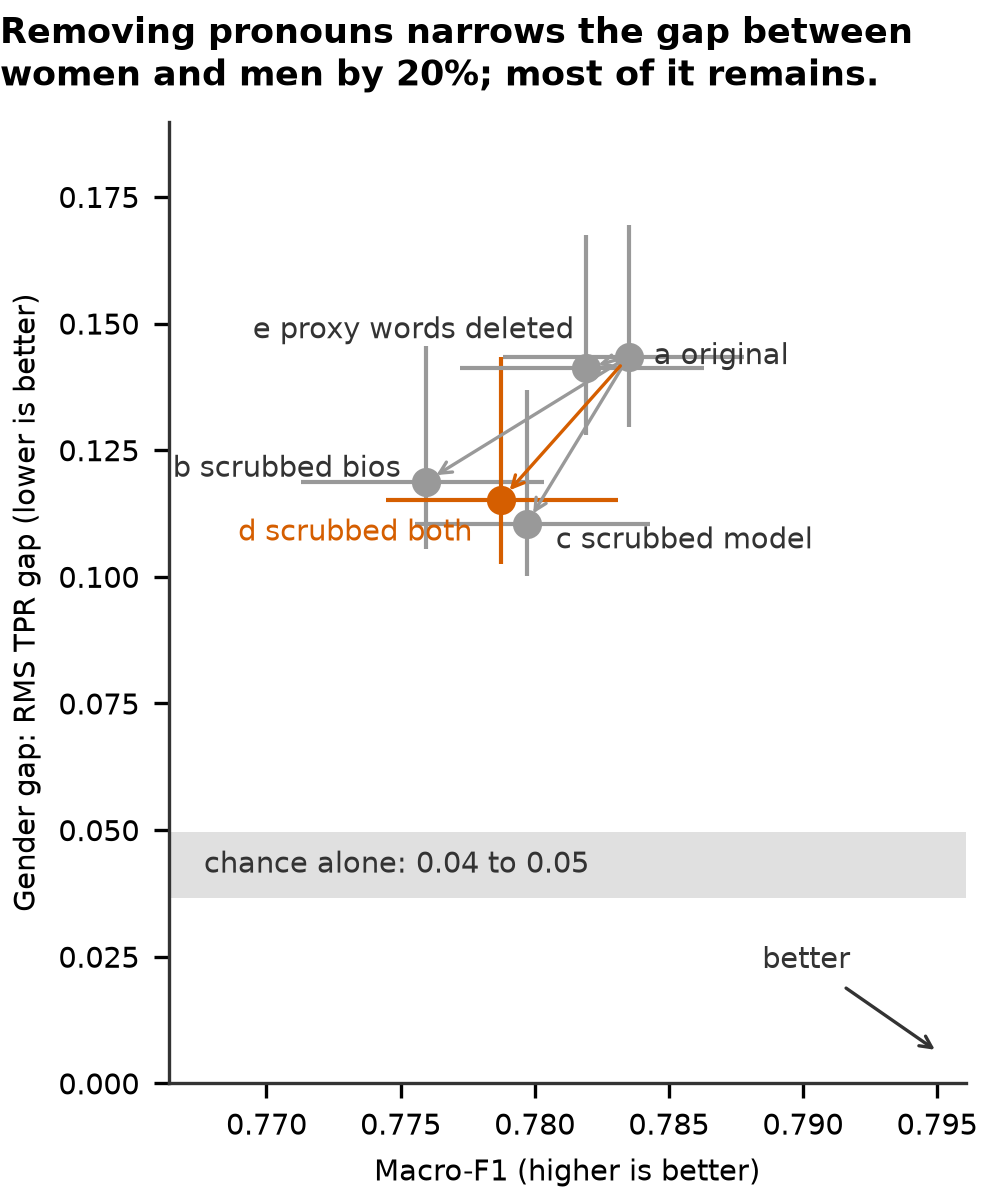

In [28]:
show_figure("f7_mitigation.png")

In [29]:
mitigation = read_json("mitigation.json")
proxy = read_json("proxy_words.json")
conditions = mitigation["conditions"]
evaluation = mitigation["evaluation_set"]
say(
    "**How this was run.** `uv run python scripts/train_scrubbed.py` trains the main model again "
    "on scrubbed bios with the same recipe. `uv run python scripts/proxy_words.py` picks the "
    f"proxy words with a rule fixed before the evaluation: {listing(proxy['words'])}. "
    f"`uv run python scripts/mitigation.py` scores {len(conditions)} conditions, each a model on a "
    "text, on the "
    f"{evaluation['bios_scored']:,} test bios outside the showcase subset, with "
    f"{mitigation['settings']['n_bootstrap']:,} bootstrap resamples and "
    f"{mitigation['settings']['n_permutations']:,} shuffles of gender for the chance level."
)

**How this was run.** `uv run python scripts/train_scrubbed.py` trains the main model again on scrubbed bios with the same recipe. `uv run python scripts/proxy_words.py` picks the proxy words with a rule fixed before the evaluation: born, currently, freeones, gallery, ranked and registered. `uv run python scripts/mitigation.py` scores 5 conditions, each a model on a text, on the 97,348 test bios outside the showcase subset, with 1,000 bootstrap resamples and 1,000 shuffles of gender for the chance level.

In [30]:
labels = {
    "a": "a. original model, raw bios",
    "b": "b. original model, scrubbed bios",
    "c": "c. scrubbed model, raw bios",
    "d": "d. scrubbed model, scrubbed bios",
    "e": "e. original model, proxy words deleted",
}
scored = {key: conditions[key]["outside_showcase"] for key in labels}
chance = scored["a"]["rms_tpr_gap"]["null"]
assert min(s["rms_tpr_gap"]["value"] for s in scored.values()) > chance["p95"]
assert scored["d"]["change_from_a"]["rms_tpr_gap"]["ci_high"] < 0
assert scored["e"]["change_from_a"]["rms_tpr_gap"]["ci_high"] > 0


def change(key, metric, digits):
    if key == "a":
        return ""
    return ci(scored[key]["change_from_a"][metric], digits, sign=True)


rows = [
    [
        labels[key],
        ci(scored[key]["macro_f1"], 3),
        ci(scored[key]["rms_tpr_gap"], 3),
        change(key, "rms_tpr_gap", 3),
        change(key, "macro_f1", 3),
    ]
    for key in labels
]
say(
    f"**What I found.** Scrubbing narrows the gap: the scrubbed model on scrubbed bios (d) brings "
    f"it from {scored['a']['rms_tpr_gap']['value']:.3f} to "
    f"{scored['d']['rms_tpr_gap']['value']:.3f} "
    f"at a cost of {-scored['d']['change_from_a']['macro_f1']['value']:.3f} in "
    "macro-F1. The gap that is "
    f"left is well above what chance gives: shuffled genders give {chance['mean']:.3f} on "
    f"average and {chance['p95']:.3f} at the {LEVEL_NUMBER}th percentile, and every "
    f"condition stays above that. Deleting the proxy words changes the gap by "
    f"{scored['e']['change_from_a']['rms_tpr_gap']['value']:+.4f}, an interval that includes zero; "
    f"{pct(mitigation['bios_changed']['proxy_word_share'])} of the test bios contain one of them."
)
say(
    md_table(
        [
            "Condition",
            "Macro-F1",
            "Gender gap",
            "Change in the gap from a",
            "Change in macro-F1 from a",
        ],
        rows,
    )
)

**What I found.** Scrubbing narrows the gap: the scrubbed model on scrubbed bios (d) brings it from 0.143 to 0.115 at a cost of 0.005 in macro-F1. The gap that is left is well above what chance gives: shuffled genders give 0.037 on average and 0.050 at the 95th percentile, and every condition stays above that. Deleting the proxy words changes the gap by -0.0023, an interval that includes zero; 12% of the test bios contain one of them.

| Condition | Macro-F1 | Gender gap | Change in the gap from a | Change in macro-F1 from a |
|---|---|---|---|---|
| a. original model, raw bios | 0.784 [0.779, 0.788] | 0.143 [0.130, 0.169] |  |  |
| b. original model, scrubbed bios | 0.776 [0.771, 0.780] | 0.119 [0.105, 0.145] | -0.025 [-0.035, -0.012] | -0.008 [-0.010, -0.005] |
| c. scrubbed model, raw bios | 0.780 [0.776, 0.784] | 0.110 [0.100, 0.137] | -0.033 [-0.046, -0.018] | -0.004 [-0.006, -0.001] |
| d. scrubbed model, scrubbed bios | 0.779 [0.774, 0.783] | 0.115 [0.103, 0.143] | -0.028 [-0.043, -0.012] | -0.005 [-0.008, -0.002] |
| e. original model, proxy words deleted | 0.782 [0.777, 0.786] | 0.141 [0.128, 0.167] | -0.002 [-0.005, +0.000] | -0.002 [-0.002, -0.001] |

In [31]:
jobs = ["model", "nurse", "surgeon"]
rows = [
    [name(job), *(ci(scored[key]["tpr_gap"][job], 1, PER, sign=True) for key in labels)]
    for job in jobs
]
say(
    f"In the jobs with the largest gaps the model keeps passing on more qualified people of one "
    f"gender. The table gives women minus men: how many more qualified women than qualified men "
    f"the model passes on, per {PER} of each. For the job {name(jobs[0])}, "
    f"the original model passes on "
    f"{scored['a']['tpr_gap'][jobs[0]]['value'] * PER:.0f} more women than men, and "
    f"{scored['d']['tpr_gap'][jobs[0]]['value'] * PER:.0f} more after scrubbing."
)
say(md_table(["Job", *(key for key in labels)], rows))

In the jobs with the largest gaps the model keeps passing on more qualified people of one gender. The table gives women minus men: how many more qualified women than qualified men the model passes on, per 100 of each. For the job model, the original model passes on 44 more women than men, and 40 more after scrubbing.

| Job | a | b | c | d | e |
|---|---|---|---|---|---|
| model | +43.8 [+36.3, +51.1] | +41.0 [+33.3, +48.2] | +40.7 [+33.2, +48.2] | +40.0 [+32.6, +47.9] | +42.3 [+34.8, +49.8] |
| nurse | +10.8 [+5.5, +16.3] | +7.5 [+2.6, +12.6] | +6.8 [+2.0, +11.4] | +5.6 [+0.9, +10.5] | +11.1 [+5.8, +16.7] |
| surgeon | -21.7 [-27.2, -16.1] | -17.3 [-22.8, -11.2] | -17.7 [-23.2, -12.3] | -18.0 [-23.4, -12.5] | -21.7 [-27.2, -16.1] |

**What it means.** Removing the pronouns is a cheap fix that does part of the work: it narrows the
gap and costs little accuracy. It leaves the screener unequal. In the jobs where the gap is
largest, a recruiter's search still passes on far more of the qualified people of one gender than
of the other. What is left sits in words and writing habits that the pronoun list misses, and in
what the model has built from them. Deleting a handful of proxy words leaves the gap where it was,
so the model reads gender from far more than these words. Each model has one training run, so the
difference between the original and the scrubbed model includes run-to-run variation that I did
not measure. Methods that act on the model's own representation (LEACE, INLP) are the next step;
I did not run them. Whatever the fix, the gap per job should be measured on every new model before
it is used. See ADR 0007.

## Does an LLM screener behave the same?

**Why I look at it.** Many companies now let a general-purpose LLM read a bio and decide who goes
to an interview. F4 tested one trained classifier by swapping pronouns. An LLM I cannot open has
to be tested from outside: the same bio goes in with different names, and I watch whether the
answer changes. I also read the reason the model writes with each answer.

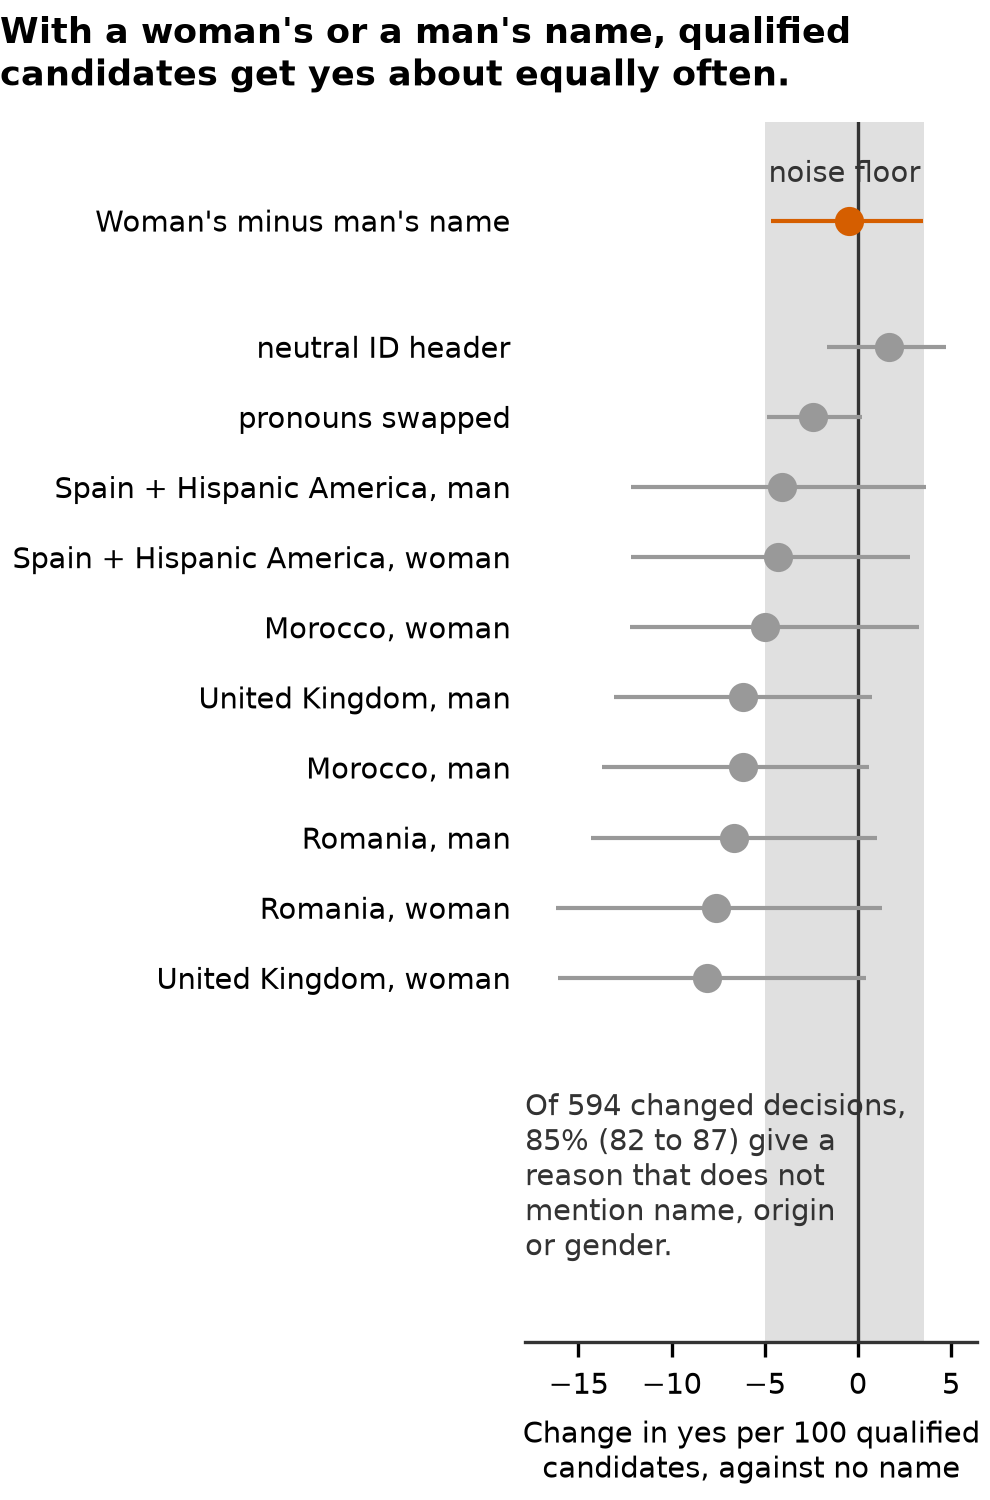

In [32]:
show_figure("f8_llm_screener.png")

In [33]:
audit = read_json("llm_audit.json")
card, llm_settings, cost = audit["model_card"], audit["settings"], audit["run_cost"]
profiles, arms, stats = audit["profiles"], audit["arms"], audit["statistics"]
assert not llm_settings["chat_template_kwargs"]["enable_thinking"]
say(
    f"**How this was run.** `uv run python scripts/llm_run.py` asks {card['huggingface']} "
    f"({card['base_model']} with {card['quantization']} weights, licence {card['licence']}), "
    f"served on the laptop, for a yes or a no on a job ad and a bio. Temperature "
    f"{llm_settings['temperature']}, seed {llm_settings['seed']}, thinking off. There are "
    f"{profiles['n_profiles']} profiles: for each job, {profiles['n_match']} qualified candidates "
    f"and {profiles['n_nonmatch']} who are not. Each profile goes in {len(arms)} ways (arms): the "
    "bio alone, with a neutral ID line, with the pronouns swapped, and with a name line for each "
    "origin group and gender. Names come from Spain, Morocco, Romania, Hispanic America and the "
    "United Kingdom; Spain and Hispanic America form one group because the model could not tell "
    f"their names apart. {cost['n_calls']:,} calls took "
    f"{cost['seconds_total'] / HOUR:.1f} hours; `uv run python scripts/llm_analyse.py` writes "
    "`results/llm_audit.json`."
)

**How this was run.** `uv run python scripts/llm_run.py` asks prism-ml/Ternary-Bonsai-2-9B-gguf (Qwen/Qwen3.5-9B with ternary 2-bit (PQ2_0) weights, licence Apache-2.0), served on the laptop, for a yes or a no on a job ad and a bio. Temperature 0, seed 42, thinking off. There are 600 profiles: for each job, 70 qualified candidates and 30 who are not. Each profile goes in 11 ways (arms): the bio alone, with a neutral ID line, with the pronouns swapped, and with a name line for each origin group and gender. Names come from Spain, Morocco, Romania, Hispanic America and the United Kingdom; Spain and Hispanic America form one group because the model could not tell their names apart. 8,167 calls took 3.0 hours; `uv run python scripts/llm_analyse.py` writes `results/llm_audit.json`.

In [34]:
GENDERS = {"female": "Woman's name", "male": "Man's name"}
PLAIN = {"none": "No header", "neutral": "Neutral ID line", "swap": "Pronouns swapped"}


def arm_label(arm):
    kind, *rest = arm.split("|")
    if kind != "name":
        return PLAIN[arm]
    origin, gender = rest
    return f"{GENDERS[gender]}, {origin.replace(' + ', ' and ')}"


order = [*PLAIN, *(arm for arm in arms if arm.startswith("name"))]
rows = [
    [
        arm_label(arm),
        ci(stats[f"tpr|{arm}"], 0, PER),
        "" if arm == "none" else ci(stats[f"diff_tpr|{arm}"], 1, PER, sign=True),
    ]
    for arm in order
]
primary, pooled = stats["primary"], stats["pooled_names_vs_none"]
widest = PER * max(abs(primary["ci_low"]), abs(primary["ci_high"]))
groups = ["Morocco", "Romania", "Spain + Hispanic America"]
assert primary["ci_low"] < 0 < primary["ci_high"] and pooled["ci_high"] < 0
assert min(audit["holm"][f"vs_uk|{group}"] for group in groups) > alpha
say(
    f"**What I found.** Without a header the model says yes to "
    f"{PER * stats['tpr|none']['value']:.0f} of every {PER} qualified candidates. The main "
    "comparison is qualified candidates with a woman's name minus those with a man's name, "
    f"pooled over jobs and origins: {ci(primary, 1, PER, sign=True)} points. The interval rules "
    f"out gaps larger than {widest:.1f} points, not smaller ones. Against the United Kingdom, "
    + ", ".join(
        f"{group.replace(' + ', ' and ')} {ci(stats[f'vs_uk|{group}'], 1, PER, sign=True)}"
        for group in groups
    )
    + "; after the Holm correction none is distinguishable from zero."
)
say(
    md_table(
        ["Presentation", f"Yes, of every {PER} qualified candidates", "Change in points"], rows
    )
)

**What I found.** Without a header the model says yes to 59 of every 100 qualified candidates. The main comparison is qualified candidates with a woman's name minus those with a man's name, pooled over jobs and origins: -0.5 [-4.7, +3.5] points. The interval rules out gaps larger than 4.7 points, not smaller ones. Against the United Kingdom, Morocco +1.5 [-5.3, +9.1], Romania +0.0 [-7.8, +7.8], Spain and Hispanic America +3.0 [-4.1, +9.3]; after the Holm correction none is distinguishable from zero.

| Presentation | Yes, of every 100 qualified candidates | Change in points |
|---|---|---|
| No header | 59 [55, 64] |  |
| Neutral ID line | 61 [56, 65] | +1.7 [-1.7, +4.8] |
| Pronouns swapped | 57 [52, 61] | -2.4 [-4.9, +0.2] |
| Woman's name, Morocco | 54 [46, 63] | -5.0 [-12.3, +3.3] |
| Man's name, Morocco | 53 [46, 60] | -6.2 [-13.7, +0.6] |
| Woman's name, Romania | 51 [42, 60] | -7.6 [-16.2, +1.3] |
| Man's name, Romania | 52 [44, 61] | -6.7 [-14.3, +1.0] |
| Woman's name, Spain and Hispanic America | 55 [46, 62] | -4.3 [-12.2, +2.8] |
| Man's name, Spain and Hispanic America | 55 [47, 64] | -4.0 [-12.2, +3.6] |
| Woman's name, United Kingdom | 51 [42, 60] | -8.1 [-16.1, +0.4] |
| Man's name, United Kingdom | 53 [45, 60] | -6.2 [-13.1, +0.8] |

In [35]:
noise = audit["noise_floor"]
name_flips = [noise["arms"][arm]["flip_rate"]["value"] for arm in arms if arm.startswith("name")]
sensitivity = audit["prompt_sensitivity"]
beyond = audit["rationalization"]["beyond_noise"]
hand = audit["rationalization"]["hand_check"]
say(
    f"But a name changes the answer. Pooled over the name arms, the yes-rate changes "
    f"by {ci(pooled, 1, PER, sign=True)} points against no header; the neutral ID line "
    f"does not do this. "
    f"The decision changes for {pct(min(name_flips))} to {pct(max(name_flips))} of the "
    f"profiles in each name arm, against {pct(noise['edit']['flip_rate']['value'])} for a "
    f"whitespace edit and {pct(noise['rerun']['flip_rate']['value'])} for an identical "
    f"rerun. Rewording the instruction matters more than any name: with the "
    f"reworded instructions and no header the yes-rate "
    f"is {PER * sensitivity['v2']['tpr']:.0f} and {PER * sensitivity['v3']['tpr']:.0f} of every "
    f"{PER} qualified candidates, and {pct(sensitivity['v2']['flip_rate_against_v1'])} and "
    f"{pct(sensitivity['v3']['flip_rate_against_v1'])} of the decisions change."
)
say(
    f"I also read the reason the model writes. Of the {beyond['n_flips']} decisions that changed "
    f"more than noise explains, {pct(beyond['share_no_mention']['value'])} ({LEVEL} interval "
    f"{pct(beyond['share_no_mention']['ci_low'])} to {pct(beyond['share_no_mention']['ci_high'])}) "
    "have a reason that does not mention name, origin, nationality or gender by the keyword rule. "
    f"I labelled {hand['n']} of them by hand: the rule agrees on {hand['n_rule_agrees']}, and by "
    f"hand {pct(hand['share_no_mention_by_hand']['value'])} do not mention them."
)

But a name changes the answer. Pooled over the name arms, the yes-rate changes by -6.0 [-10.1, -2.1] points against no header; the neutral ID line does not do this. The decision changes for 10% to 15% of the profiles in each name arm, against 5% for a whitespace edit and 0% for an identical rerun. Rewording the instruction matters more than any name: with the reworded instructions and no header the yes-rate is 47 and 39 of every 100 qualified candidates, and 13% and 16% of the decisions change.

I also read the reason the model writes. Of the 594 decisions that changed more than noise explains, 85% (95% interval 82% to 87%) have a reason that does not mention name, origin, nationality or gender by the keyword rule. I labelled 50 of them by hand: the rule agrees on 45, and by hand 82% do not mention them.

**What it means.** For this model, this prompt and these jobs, the gender and the origin of a name
do not move the yes-rate by more than I can measure, which is a few points. This is a null result:
a small gap of a few points could hide in these intervals. What does move the answer is having a
name at all, and how the instruction is worded. A name makes the model stricter. The pooled
comparison against no header was not in my plan, so I read it as a lead. The reasons for the
changes mostly do not mention the name. They do not cover for a gender or origin effect; they
explain changes that a name sets off by other routes, such as a mismatch with a name inside the
bio. This does not show that the reasons are always honest: it rests on a few reasons read by one
reader with one rule. The limits are one model, one prompt with rewordings, a few jobs and
profiles, and noise bands from a small set of profiles. See ADR 0008.